<div style="display:block;width:100%;margin:auto;" direction=rtl align=center>
    <br><br>
    <div style="width:100%;margin:100;display:block;background-color:#fff0;" display=block align=center>
        <table style="border-style:hidden;border-collapse:collapse;">
            <tr>
                <td style="border: none!important;">
                    <img width=130 align=right src="https://i.ibb.co/yXKQmtZ/logo1.png" style="margin:0;" />
                </td>
                <td style="text-align:center;border: none!important;">
                    <h1 align=center><font size=5 color="#045F5F"> <b> Design and Analysis of Deep Neural Networks</b><br><br>Computer Assignment Bonus</font></h1>
                </td>
                <td style="border: none!important;">
                    <img width=170 align=left src="https://i.ibb.co/wLjqFkw/logo2.png" style="margin:0;" />
                </td>
            </tr>
        </table>
        <h2> Farzad Jannati - 810103099 </h2>
        <h1> Instructor: Dr. Ahmad Kalhor </h1>
    </div>
</div>

>[Visual Question Answering with PaliGemma: Efficient Fine-Tuning via QLoRA](#scrollTo=c5ou0fpDYzrn)

>>[I. Environment Setup & Dependencies](#scrollTo=ZPR7tZVxYzrn)

>>>[Installing Required Libraries](#scrollTo=sCwLDdZQYzrn)

>>>[Importing Modules & Setting Device](#scrollTo=3FTUlTzgYzrn)

>>[II. Data Acquisition & Preprocessing Pipeline](#scrollTo=wwX7bCKnYzro)

>>>[Loading the CLEVR Dataset](#scrollTo=YZhY-ndTYzro)

>>>[Data Filtering & Splitting](#scrollTo=EKAsqU3zYzro)

>>[Load model](#scrollTo=CHxUweIYYzro)

>>[ROUGE SCORE (Before fine tuning)](#scrollTo=23lf3PdTYzrp)

>>[IV. Fine-Tuning](#scrollTo=ObJT57OqYzrp)

>>>[4.2. Trainer Initialization (Integrating Model, Data, and Args)](#scrollTo=YkRGRHysYzrp)

>>>[4.3. Execution of Training Loop (Running trainer.train())](#scrollTo=MS5pNYqzYzrp)

>>[ROUGE SCORE (After fine tuning)](#scrollTo=SW262-JWYzrp)

>>[VI. Inference & Qualitative Analysis](#scrollTo=BPj8WBXNYzrp)



# Visual Question Answering with PaliGemma: Efficient Fine-Tuning via QLoRA

## I. Environment Setup & Dependencies

### Installing Required Libraries

In [ ]:
# !pip install -q -U datasets bitsandbytes gdown peft
# !pip install -q git+https://github.com/huggingface/transformers.git
# !pip -q install evaluate
# !pip -q install ipython
# !pip install tensorboard
# !pip install -q absl-py nltk rouge-score
# !pip install --force-reinstall numpy==1.26.4

In [ ]:
import numpy as np
print(np.__version__)

1.26.4


### Importing Modules & Setting Device

In [ ]:
from transformers import PaliGemmaProcessor
from transformers import BitsAndBytesConfig, PaliGemmaForConditionalGeneration
from peft import get_peft_model, LoraConfig
import torch
import evaluate
from transformers import TrainingArguments
import numpy as np
from transformers import Trainer
from huggingface_hub import login
import datasets
from datasets import Dataset, DatasetDict
import matplotlib.pyplot as plt
from PIL import Image
import textwrap
from random import sample
import random
from tqdm import tqdm
from evaluate import load
from datasets import load_dataset
from IPython.display import display

device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [ ]:
device

'cuda'

## II. Data Acquisition & Preprocessing Pipeline

### Loading the CLEVR Dataset

In [ ]:
# Define the dataset details
dataset_name = "HuggingFaceM4/clevr"
config_name = "default"
split = "train"

# Download the dataset
print(f"Downloading and saving the dataset: {dataset_name}...")
dataset = load_dataset(dataset_name, config_name, split=split)

print(f"Selecting 2% of the train dataset: {int(0.02 * len(dataset))} samples")

subset = dataset.select(range(0, 14000))
# Save the dataset locally
subset.save_to_disk("dataset/train_dataset")
print(f"Dataset saved successfully")

README.md:   0%|          | 0.00/352 [00:00<?, ?B/s]

clevr.py:   0%|          | 0.00/5.36k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/5.50k [00:00<?, ?B/s]

The repository for HuggingFaceM4/clevr contains custom code which must be executed to correctly load the dataset. You can inspect the repository content at https://hf.co/datasets/HuggingFaceM4/clevr.
You can avoid this prompt in future by passing the argument `trust_remote_code=True`.

Do you wish to run the custom code? [y/N]  غ
The repository for HuggingFaceM4/clevr contains custom code which must be executed to correctly load the dataset. You can inspect the repository content at https://hf.co/datasets/HuggingFaceM4/clevr.
You can avoid this prompt in future by passing the argument `trust_remote_code=True`.

Do you wish to run the custom code? [y/N]  y


Repo card metadata block was not found. Setting CardData to empty.


...

Generating validation split:   0%|          | 0/149991 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/149988 [00:00<?, ? examples/s]

Selecting 2% of the train dataset: 13999 samples


Saving the dataset (0/6 shards):   0%|          | 0/14000 [00:00<?, ? examples/s]

Dataset saved successfully


### Data Filtering & Splitting

In [ ]:
# Define the dataset details
dataset_name = "HuggingFaceM4/clevr"
config_name = "default"
split = "validation"

# Download the dataset
print(f"Downloading and saving the dataset: {dataset_name}...")
dataset = load_dataset(dataset_name, config_name, split=split)

# Seed for reproducibility
random.seed(42)

# Calculate the number of samples (2%)
subset_size = 3000
print(f"Selecting 2% of the validation dataset: {int(0.02 * len(dataset))} samples")

# Select 2% of the dataset
subset_indices = random.sample(range(len(dataset)), subset_size)
subset = dataset.select(subset_indices)

# Save the dataset locally
subset.save_to_disk("dataset/validation_dataset")
print(f"Dataset saved successfully")

Repo card metadata block was not found. Setting CardData to empty.


Selecting 2% of the validation dataset: 2999 samples


Saving the dataset (0/2 shards):   0%|          | 0/3000 [00:00<?, ? examples/s]

Dataset saved successfully


In [ ]:
train_dataset = Dataset.load_from_disk("dataset/train_dataset")
test_dataset = Dataset.load_from_disk("dataset/validation_dataset")

test_dataset, val_dataset = test_dataset.train_test_split(test_size=3000-2025, seed=42).values()

inference_dataset, val_dataset  = val_dataset.train_test_split(test_size=len(val_dataset)-10, seed=42).values()

cols_remove = ["question_index", "question_family_index", "image_filename", "split", "image_index","program"]
train_dataset = train_dataset.remove_columns(cols_remove)
test_dataset = test_dataset.remove_columns(cols_remove)
inference_dataset = inference_dataset.remove_columns(cols_remove)

In [ ]:
print(f"Number of train dataset : {len(train_dataset)}")
print(f"Number of validation dataset : {len(val_dataset)}")
print(f"Number of test dataset : {len(test_dataset)}")
print(f"Number of inference dataset : {len(inference_dataset)}")

Number of train dataset : 14000
Number of validation dataset : 965
Number of test dataset : 2025
Number of inference dataset : 10


In [ ]:
model_name = "leo009/paligemma-3b-pt-224"

processor = PaliGemmaProcessor.from_pretrained(model_name)

def tokenize_text(text):
    return processor.tokenizer.tokenize(text)

preprocessor_config.json:   0%|          | 0.00/699 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/40.0k [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/4.26M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.5M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/24.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/607 [00:00<?, ?B/s]

In [ ]:
elements = set()
for pr in train_dataset['answer']:
    elements.add(len(tokenize_text(pr)))

print("Number of tokens in each answer: ", elements)

Number of tokens in each answer:  {1}


In [ ]:
def inference(model, processor, data, device):

    img = data['image'].convert("RGB")
    prompt = "answer " + data['question']
    ans = data['answer']

    # Add the required <image> tokens to the prompt text
    num_images = len(img) if isinstance(img, list) else 1
    image_tokens = " ".join(["<image>"] * num_images)

    # Prepend the <image> tokens to the prompt
    enhanced_prompt = f"{image_tokens} {prompt}"

    # Process the inputs
    inputs = processor(img, enhanced_prompt, return_tensors="pt").to(device)

    # Generate output
    output = model.generate(**inputs, max_new_tokens=20)

    # Decode the generated text and print the original data
    print("Question:",data['question'])
    print("Original Answer:",ans)
    print("Model Answer:",processor.decode(output[0]).split("<bos>")[1].split("\n")[1].split('<eos>')[0])
    display(img)

## Load model

In [ ]:
bnb_config = BitsAndBytesConfig(
    load_in_4bit= True,
    bnb_4bit_quant_type= "nf4",
    bnb_4bit_compute_dtype= torch.float16,
    bnb_4bit_use_double_quant= False,
)

model_name = "leo009/paligemma-3b-pt-224"

# Load Preprocess Dataset
processor = PaliGemmaProcessor.from_pretrained(model_name)

# Define the collate_fn
def collate_fn(examples):
  texts = ["<image> answer " + example["question"] for example in examples]
  labels= [example['answer'] for example in examples]
  images = [example["image"].convert("RGB") for example in examples]
  tokens = processor(text=texts, images=images, suffix=labels,
                    return_tensors="pt", padding="longest")

  tokens = tokens.to(torch.bfloat16).to(device)
  return tokens

# Load Paligemma Model with Quantization
model = PaliGemmaForConditionalGeneration.from_pretrained(
    model_name,
    quantization_config=bnb_config,
    device_map="auto",
)

config.json:   0%|          | 0.00/1.03k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/62.6k [00:00<?, ?B/s]

model-00001-of-00003.safetensors:   0%|          | 0.00/4.95G [00:00<?, ?B/s]

model-00002-of-00003.safetensors:   0%|          | 0.00/5.00G [00:00<?, ?B/s]

model-00003-of-00003.safetensors:   0%|          | 0.00/1.74G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/137 [00:00<?, ?B/s]

Question: Is the number of big cyan rubber objects behind the small green rubber sphere greater than the number of blue shiny cubes?
Original Answer: yes
Model Answer: no


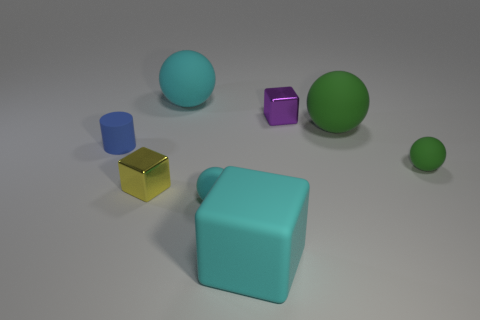

In [ ]:
# Inference on a inference dataset sample

inference(model, processor, inference_dataset[0], device)

Question: There is a tiny metallic thing that is both on the left side of the large blue block and to the right of the small cyan metal thing; what color is it?
Original Answer: red
Model Answer: gold


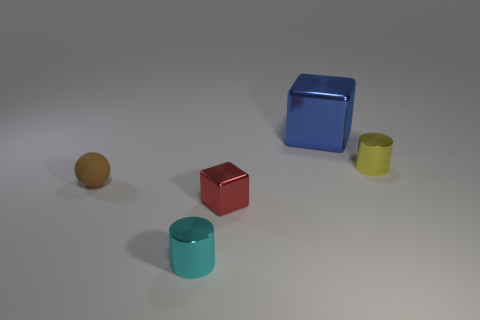

In [ ]:
# Inference on a inference dataset sample

inference(model, processor, inference_dataset[4], device)

## ROUGE SCORE (Before fine tuning)

In [ ]:
# Load ROUGE metric
rouge = load("rouge")

def compute_rouge(model, processor, dataset, device):

    predictions = []
    references = []

    for data in tqdm(dataset, desc="Processing Dataset"):
        img = data['image'].convert("RGB")
        prompt = "answer " + data['question']
        ans = data['answer']

        # Add the required <image> tokens to the prompt text
        num_images = len(img) if isinstance(img, list) else 1
        image_tokens = " ".join(["<image>"] * num_images)

        # Prepend the <image> tokens to the prompt
        enhanced_prompt = f"{image_tokens} {prompt}"

        # Process the inputs
        inputs = processor(img, enhanced_prompt, return_tensors="pt").to(device)

        # Generate output
        output = model.generate(**inputs, max_new_tokens=30)

        # Decode the generated text and print the original data
        generated_text = processor.decode(output[0]).split("<bos>")[1].split("\n")[1].split('<eos>')[0]

        # Append to predictions and references
        predictions.append(generated_text.strip())
        references.append(ans.strip())

    # Compute ROUGE scores
    rouge_scores = rouge.compute(predictions=predictions, references=references,tokenizer=processor.tokenizer.tokenize)
    return rouge_scores


In [ ]:
# Compute ROUGE scores for the test dataset Before fine tuning
bff_rouge_scores = compute_rouge(model, processor, test_dataset, device)

# Print the results
print("ROUGE Scores Before Fine Tuning:", bff_rouge_scores)

Processing Dataset: 100%|██████████| 2025/2025 [07:14<00:00,  4.66it/s]


ROUGE Scores Before Fine Tuning: {'rouge1': 0.34074074074074073, 'rouge2': 0.0, 'rougeL': 0.3402469135802469, 'rougeLsum': 0.3397530864197531}


## IV. Fine-Tuning

In [ ]:
# Configure LoRA with low-rank adaptation parameters
lora_config = LoraConfig(
    r=16,
    target_modules=["q_proj", "o_proj", "k_proj", "v_proj", "gate_proj", "up_proj", "down_proj"],  # Specify target model layers for LoRA
    task_type="CAUSAL_LM",  # Define the task type as causal language modeling
)

# Apply the LoRA configuration to the base model
model = get_peft_model(model, lora_config)

# Display the count of trainable parameters after applying LoRA
model.print_trainable_parameters()


trainable params: 22,597,632 || all params: 2,946,064,112 || trainable%: 0.7670


### 4.2. Trainer Initialization (Integrating Model, Data, and Args)

In [ ]:

# Training Arguments
training_args = TrainingArguments(
    output_dir=                     "./results",
    eval_strategy=                  "steps",
    eval_steps=                     100,
    save_strategy=                  "steps",
    save_steps=                     1000,
    learning_rate=                  2e-4,
    num_train_epochs=               2,
    per_device_train_batch_size=    4,
    per_device_eval_batch_size=     4,
    gradient_accumulation_steps=    5,
    optim=                          "paged_adamw_8bit",
    fp16=                           True,
    overwrite_output_dir =          True,
    logging_dir=                    "./logs",
    logging_steps=                  100,
    save_total_limit=               1,
    report_to=                      ["tensorboard"],
    dataloader_pin_memory=          False,
    remove_unused_columns=          False
)

# Trainer
trainer = Trainer(
    model=          model,
    args=           training_args,
    train_dataset=  train_dataset,
    eval_dataset=   val_dataset,
    data_collator=  collate_fn
)

/usr/local/lib/python3.10/dist-packages/accelerate/accelerator.py:494: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler(**kwargs)


### 4.3. Execution of Training Loop (Running trainer.train())

In [ ]:
tr = trainer.train()

Step,Training Loss,Validation Loss
100,3.051600,0.442348
200,2.221400,0.425512
300,2.087800,0.395004
400,1.992200,0.384040
500,1.916000,0.384241
600,1.906800,0.351204
700,1.830800,0.335283
800,1.519400,0.318250
900,1.450700,0.318286
1000,1.444200,0.311379


In [ ]:
trainer.save_model("./fine_tuned_model")

## ROUGE SCORE (After fine tuning)

In [ ]:
# Compute ROUGE scores for the test dataset After fine tuning
f_rouge_scores = compute_rouge(model, processor, test_dataset, device)

# Print the results
print("ROUGE Scores After Fine Tuning:", f_rouge_scores)

Processing Dataset: 100%|██████████| 2025/2025 [11:20<00:00,  2.98it/s]


ROUGE Scores After Fine Tuning: {'rouge1': 0.6908641975308641, 'rouge2': 0.0, 'rougeL': 0.6898765432098766, 'rougeLsum': 0.691111111111111}


## VI. Inference & Qualitative Analysis

Processing sample 1/10
Question: Is the number of big cyan rubber objects behind the small green rubber sphere greater than the number of blue shiny cubes?
Original Answer: yes
Model Answer: yes


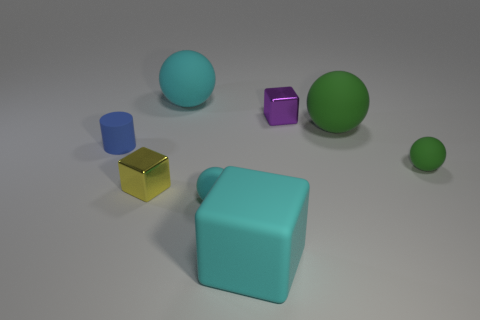

Processing sample 2/10
Question: Are there an equal number of big gray cylinders on the right side of the rubber thing and brown things that are to the right of the large red object?
Original Answer: yes
Model Answer: no


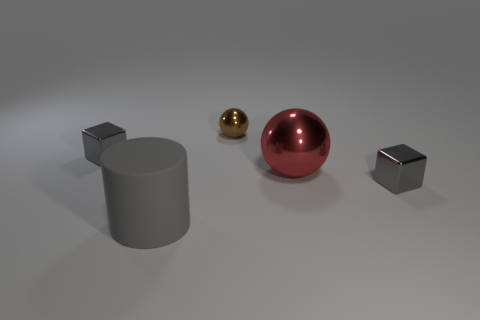

Processing sample 3/10
Question: Is there a matte sphere that is in front of the matte thing in front of the big matte thing that is on the left side of the blue rubber object?
Original Answer: no
Model Answer: no


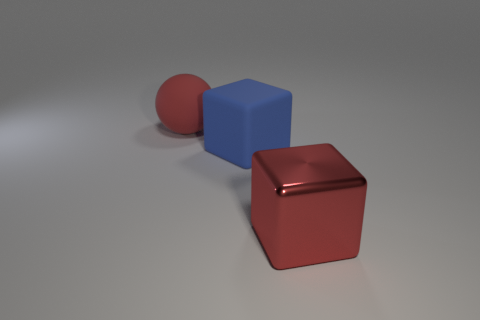

Processing sample 4/10
Question: Are there any other things that have the same material as the small purple cylinder?
Original Answer: no
Model Answer: no


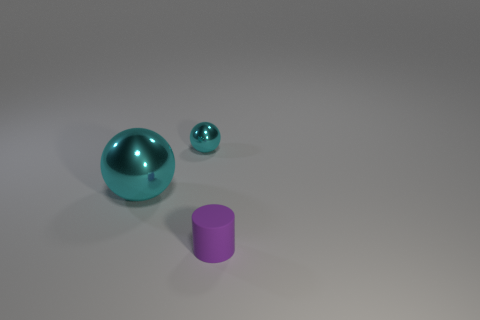

Processing sample 5/10
Question: There is a tiny metallic thing that is both on the left side of the large blue block and to the right of the small cyan metal thing; what color is it?
Original Answer: red
Model Answer: yellow


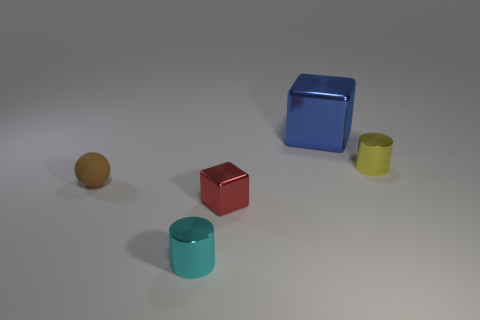

Processing sample 6/10
Question: How many tiny red cubes have the same material as the tiny cyan object?
Original Answer: 0
Model Answer: 0


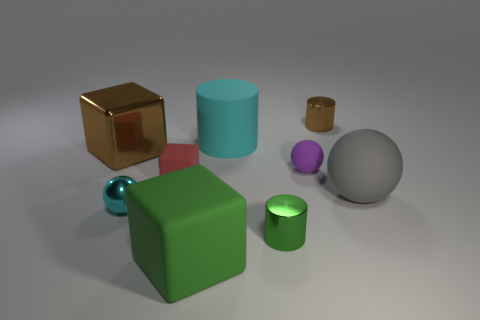

Processing sample 7/10
Question: Are there an equal number of big metal objects and big yellow shiny things?
Original Answer: no
Model Answer: yes


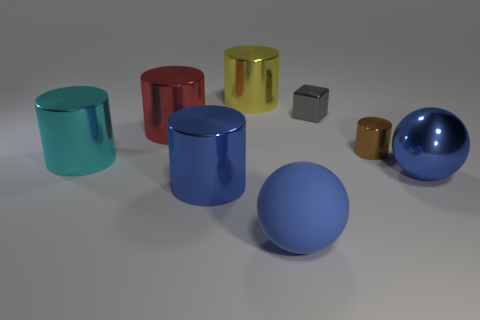

Processing sample 8/10
Question: Is the color of the tiny matte ball the same as the big cylinder?
Original Answer: yes
Model Answer: yes


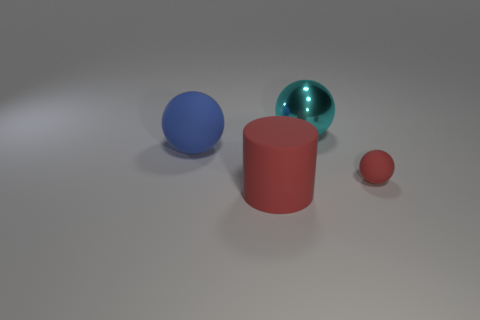

Processing sample 9/10
Question: There is a metal object that is both behind the cyan matte object and right of the tiny red cylinder; what is its color?
Original Answer: blue
Model Answer: gray


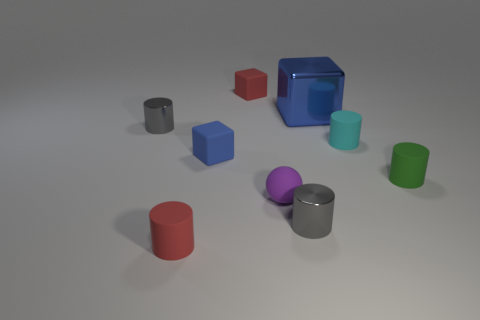

Processing sample 10/10
Question: Is the material of the cylinder behind the small cyan cylinder the same as the cylinder on the left side of the green metallic block?
Original Answer: no
Model Answer: no


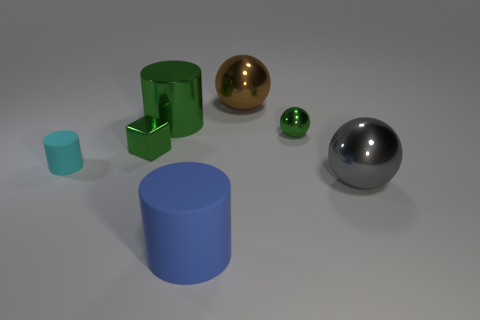

In [ ]:
# Inferencing on the inference dataset

for idx, sample in enumerate(inference_dataset):

    print(f"Processing sample {idx + 1}/{len(inference_dataset)}")
    inference(model, processor, sample, device)
